# PAPER_RESULTS

Builds the manuscript tables and figures from saved results only. NO training or tuning happens here.

Val chooses the models, TSCV assesses robustness, test evaluates the already selected models.

- Regression selected model: best fixed val R^2.
- Operationally selected model: best val simulator PR AUC at tau = 0.10.
- TSCV (first 85%) is reported as robustness ONLY.
- Test results are read only after both selections are fixed (section 5 onward).
- Threshold sensitivity (tau = 0.05-0.15) is a post-selection diagnostic.

Inputs: results/(nonlinear or nn)/ (val, test, TSCV), results/predictions/, and results/simulation/simulator_results_(validation or test).csv from STATIC_SIMULATION. Outputs go to paper_results/.

## 1. Imports and configuration

In [13]:
import json
from pathlib import Path

import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.stats.api as sms
#from scipy.stats import friedmanchisquare, rankdata, wilcoxon
# from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.metrics import auc, precision_recall_curve, roc_auc_score, roc_curve
from statsmodels.graphics.tsaplots import plot_acf

MANIFEST_PATH = Path("data/processed/manifest.json")
RESULTS_DIR = Path("results")
PREDICTION_DIR = RESULTS_DIR / "predictions"
SIM_DIR = RESULTS_DIR / "simulation"
FACTOR_TESTS_PATH = RESULTS_DIR / "nonlinear" / "preprocessing_factor_tests.csv" # NONLINEAR_MODELS files
OUT = Path("paper_results")
FAMILIES = ["nonlinear", "nn"]

NOMINAL_TOLERANCE = 0.10
TOLERANCES = [0.05, 0.075, 0.10, 0.125, 0.15]
TOP_N = 5
LEAD_S = 0
EXCLUDED_MODELS = ["dummy_baseline", "daylight_baseline"] # just for reference as bls
WRITE_LOCK_FOR_GLM = True # last cell of GENERAL_LINEAR_MODELS notebook reads results/simulation/locked_selection.json
EVENT_MERGE_GAP_S = 60
LJUNG_BOX_LAGS_MIN = [5, 10, 30, 60] # same as GENERAL_LINEAR_MODELS
RESIDUAL_ACF_MAX_LAG_MIN = 60

mpl.rc("axes", labelsize=14)
mpl.rc("xtick", labelsize=12)
mpl.rc("ytick", labelsize=12)
OUT.mkdir(parents=True, exist_ok=True)

manifest = json.loads(MANIFEST_PATH.read_text())
TZ = manifest["display_timezone"]
SAMPLING_S = manifest["sampling_s"]
NIGHTS_MS = [(a * 1000, b * 1000) for a, b in manifest["night_periods_utc_s"]]
TARGET_META = pd.DataFrame(manifest["targets"]).set_index("name")


def save_table(df, name):
    df.to_csv(OUT / f"{name}.csv", index=False)
    return df


def save_fig(name):
    plt.savefig(OUT / f"{name}.png", dpi=300, bbox_inches="tight")

## 2. Load saved results

Test subset files are not opened until section 5.

In [14]:
def load_results(name):
    frames = []
    for fam in FAMILIES:
        df = pd.read_csv(RESULTS_DIR / fam / name)
        df["model_family"] = fam
        frames.append(df)
    df = pd.concat(frames, ignore_index=True)
    df = df.rename(columns={"sampling frequency": "sampling", "model_name": "model", "target_name": "target"})
    if "lead_s" in df:
        df = df[df["lead_s"].fillna(0) == LEAD_S]
    df["config_id"] = df["sampling"] + "__" + df["target"] + "__" + df["model"]
    df["target_type"] = df["target"].map(TARGET_META["metric"])
    df["window_samples"] = df["target"].map(TARGET_META["window_samples"])
    df["variant"] = df["target"].map(TARGET_META["variant"])
    return df[~df["model"].isin(EXCLUDED_MODELS)].reset_index(drop=True)


reg_val = load_results("validation_results.csv")
tscv_sum = load_results("tscv_summary.csv")
tscv_folds = load_results("tscv_folds.csv")
sim_val = pd.read_csv(SIM_DIR / "simulator_results_validation.csv")
sim_val = sim_val[(sim_val["lead_s"] == LEAD_S) & (sim_val["split"] == "validation")]
print(f"validation regression: {len(reg_val)} configurations, simulator validation: {sim_val['config_id'].nunique()} configurations")

validation regression: 1152 configurations, simulator validation: 1296 configurations


## 3. Top 5 by fixed validation R^2 (regression selection)

In [15]:
REG_COLS = ["config_id", "sampling", "target", "model", "model_family", "target_type", "window_samples", "variant", "training_r2", "validation_r2", "validation_rmse", "n_train", "n_validation"]
top_val_reg = reg_val.sort_values("validation_r2", ascending=False).head(TOP_N)[REG_COLS]
top_val_reg.insert(0, "rank", range(1, len(top_val_reg) + 1))
save_table(top_val_reg, "top5_validation_regression")
REG_SELECTED = top_val_reg.iloc[0]["config_id"]
print(f"Regression-selected model: {REG_SELECTED}")
top_val_reg

Regression-selected model: 2MIN__RSTDEV_FWD_300_SAVGOL__rf_tuned


,rank,config_id,sampling,target,model,model_family,target_type,window_samples,variant,training_r2,validation_r2,validation_rmse,n_train,n_validation
259,1,2MIN__RSTDEV_FWD_300_SAVGOL__rf_tuned,2MIN,RSTDEV_FWD_300_SAVGOL,rf_tuned,nonlinear,RSTDEV,300.0,SAVGOL,0.689915,0.673172,0.013337,1417,308
277,2,2MIN__RSTDEV_FWD_600_DSMAX__rf_tuned,2MIN,RSTDEV_FWD_600_DSMAX,rf_tuned,nonlinear,RSTDEV,600.0,DSMAX,0.601508,0.646772,0.013886,1441,308
853,3,2MIN__RSTDEV_FWD_300_SAVGOL__gru_tuned,2MIN,RSTDEV_FWD_300_SAVGOL,gru_tuned,nn,RSTDEV,300.0,SAVGOL,0.587641,0.645446,0.013891,1381,308
857,4,2MIN__RSTDEV_FWD_300_SAVGOL__mlp_tuned,2MIN,RSTDEV_FWD_300_SAVGOL,mlp_tuned,nn,RSTDEV,300.0,SAVGOL,0.567487,0.645429,0.013891,1417,308
253,5,2MIN__RSTDEV_FWD_300_DSMAX__rf_tuned,2MIN,RSTDEV_FWD_300_DSMAX,rf_tuned,nonlinear,RSTDEV,300.0,DSMAX,0.631913,0.644195,0.012297,1441,308


## 4. Top 5 by mean TSCV R^2 (robustness only, NOT used for selection)

NN TSCV was runned for the tuned models ONLY. Missing runs (diverged in every retry) are also listed below. (All of these were failed LSTMs that had issues with exploding gradients)

In [16]:
tscv_expected = reg_val[reg_val["model"].isin(tscv_sum["model"].unique())]
tscv_missing = save_table(tscv_expected[~tscv_expected["config_id"].isin(tscv_sum["config_id"])][["config_id", "model_family"]], "tscv_missing")
print(f"TSCV missing for {len(tscv_missing)} configuration(s): {tscv_missing['config_id'].tolist()}")

TSCV_COLS = ["config_id", "sampling", "target", "model", "model_family", "n_folds", "mean_r2", "std_r2", "median_r2", "r2_ci_low", "r2_ci_high", "pooled_r2", "mean_rmse", "std_rmse"]
top_tscv = tscv_sum.sort_values("mean_r2", ascending=False).head(TOP_N)[TSCV_COLS]
top_tscv = top_tscv.merge(reg_val[["config_id", "validation_r2"]], on="config_id", how="left")
top_tscv.insert(0, "rank", range(1, len(top_tscv) + 1))
top_tscv["role"] = "robustness only" # added so I don't accidentally get confused like I did in previous notebook
save_table(top_tscv, "top5_tscv_robustness")

TSCV missing for 1 configuration(s): ['2MIN__RSTDEV_FWD_1200__lstm_tuned']


,rank,config_id,sampling,target,model,model_family,n_folds,mean_r2,std_r2,median_r2,r2_ci_low,r2_ci_high,pooled_r2,mean_rmse,std_rmse,validation_r2,role
0,1,2MIN__RSTDEV_FWD_300_DSAVG__gru_tuned,2MIN,RSTDEV_FWD_300_DSAVG,gru_tuned,nn,3,0.465491,0.132909,0.473473,0.135326,0.795656,0.526904,0.008662,0.000638,0.461458,robustness only
1,2,1MIN__REXD_FWD_300_DSMAX__xgb_tuned,1MIN,REXD_FWD_300_DSMAX,xgb_tuned,nonlinear,3,0.441520,0.136694,0.447857,0.101953,0.781088,0.505970,0.055165,0.004246,0.574215,robustness only
2,3,2MIN__RSTDEV_FWD_300_DSAVG__mlp_tuned,2MIN,RSTDEV_FWD_300_DSAVG,mlp_tuned,nn,3,0.430021,0.106894,0.389252,0.164483,0.695559,0.484509,0.008985,0.000740,0.536004,robustness only
3,4,1MIN__RSTDEV_FWD_300_DSAVG__mlp_tuned,1MIN,RSTDEV_FWD_300_DSAVG,mlp_tuned,nn,3,0.422642,0.152042,0.447420,0.044949,0.800335,0.480089,0.009311,0.000593,0.397007,robustness only
4,5,2MIN__REXD_FWD_1200_SAVGOL__mlp_tuned,2MIN,REXD_FWD_1200_SAVGOL,mlp_tuned,nn,3,0.415633,0.084957,0.368735,0.204588,0.626677,0.419308,0.128204,0.023915,0.476768,robustness only


## 5. Top 5 by validation simulator PR AUC at tau = 0.10 (operational selection)

In [17]:
SIM_COLS = ["config_id", "sampling", "target", "model", "model_family", "target_type", "window_samples", "variant", "savgol_filtered", "tolerance", "decision_threshold", "tp", "fp", "tn", "fn", "prevalence", "precision", "recall", "f1", "accuracy", "false_positive_rate", "roc_auc", "pr_auc"]
nominal_val = sim_val[np.isclose(sim_val["tolerance"], NOMINAL_TOLERANCE)]
candidates_sim = nominal_val[~nominal_val["model"].isin(EXCLUDED_MODELS)].dropna(subset=["pr_auc"])
top_val_sim = candidates_sim.sort_values(["pr_auc", "roc_auc"], ascending=False).head(TOP_N)[SIM_COLS]
top_val_sim.insert(0, "rank", range(1, len(top_val_sim) + 1))
save_table(top_val_sim, "top5_validation_simulator")
OP_SELECTED = top_val_sim.iloc[0]["config_id"]
print(f"Operationally selected model: {OP_SELECTED} (from {len(candidates_sim)} candidates)")

daylight_val = nominal_val[nominal_val["model"] == "daylight_baseline"]
print(f"Daylight baseline validation PR AUC (reference): median {daylight_val['pr_auc'].median():.4f}")
top_val_sim

Operationally selected model: 2MIN__REXD_FWD_1200_DSMAX__rnn_baseline (from 1152 candidates)
Daylight baseline validation PR AUC (reference): median 0.8380


,rank,config_id,sampling,target,model,model_family,target_type,window_samples,variant,savgol_filtered,...,tn,fn,prevalence,precision,recall,f1,accuracy,false_positive_rate,roc_auc,pr_auc
2402,1,2MIN__REXD_FWD_1200_DSMAX__rnn_baseline,2MIN,REXD_FWD_1200_DSMAX,rnn_baseline,nn,REXD,1200,DSMAX,False,...,90,68,0.659091,0.900000,0.665025,0.764873,0.730519,0.142857,0.824302,0.913175
2517,2,2MIN__REXD_FWD_1200_SAVGOL__xgb_tuned,2MIN,REXD_FWD_1200_SAVGOL,xgb_tuned,nonlinear,REXD,1200,SAVGOL,True,...,0,0,0.659091,0.659091,1.000000,0.794521,0.659091,1.000000,0.780929,0.905611
2467,3,2MIN__REXD_FWD_1200_SAVGOL__mlp_tuned,2MIN,REXD_FWD_1200_SAVGOL,mlp_tuned,nn,REXD,1200,SAVGOL,True,...,86,52,0.659091,0.888235,0.743842,0.809651,0.769481,0.180952,0.822707,0.897267
3382,4,2MIN__RSTDEV_FWD_1200_DSAVG__rf_baseline,2MIN,RSTDEV_FWD_1200_DSAVG,rf_baseline,nonlinear,RSTDEV,1200,DSAVG,False,...,68,43,0.659091,0.812183,0.788177,0.800000,0.740260,0.352381,0.798147,0.895872
1222,5,1MIN__RSTDEV_FWD_1200_DSAVG__rf_baseline,1MIN,RSTDEV_FWD_1200_DSAVG,rf_baseline,nonlinear,RSTDEV,1200,DSAVG,False,...,177,126,0.659609,0.897106,0.688889,0.779330,0.742671,0.153110,0.799805,0.895055


In [18]:
SELECTED = {"regression-selected": REG_SELECTED, "operationally selected": OP_SELECTED}
selection = {
    "regression_selected": REG_SELECTED, "regression_criterion": "max fixed-validation R^2",
    "operationally_selected": OP_SELECTED,
    "operational_criterion": f"max validation simulator PR AUC at tau = {NOMINAL_TOLERANCE}",
    "n_regression_candidates": int(len(reg_val)), "n_simulator_candidates": int(len(candidates_sim)),
    "excluded_models": EXCLUDED_MODELS, "note": "Selected on validation only; test was not used.",
}
(OUT / "selected_models.json").write_text(json.dumps(selection, indent=2))

if WRITE_LOCK_FOR_GLM:
    op = candidates_sim[candidates_sim["config_id"] == OP_SELECTED].iloc[0]
    meta = TARGET_META.loc[op["target"]]
    lock = {"sampling": op["sampling"], "target": op["target"], "model": op["model"], "model_family": op["model_family"], "metric": meta["metric"], "window_samples": int(meta["window_samples"]), "variant": meta["variant"],
            "lead_s": int(meta["lead_s"]), "window_start_offset_s": float(meta["window_start_offset_s"]), "window_end_offset_s": float(meta["window_end_offset_s"]), "tolerance": NOMINAL_TOLERANCE,
            "decision_threshold": float(op["decision_threshold"]), "event_merge_gap_s": EVENT_MERGE_GAP_S, "selection_metric": "pr_auc", "selection_value_validation": float(op["pr_auc"]),
            "n_candidates": int(len(candidates_sim)), "created_utc": pd.Timestamp.now(tz="UTC").isoformat(), "note": "Written by PAPER_RESULTS. Selected from validation-period simulation only; the test period was not used."}
    (SIM_DIR / "locked_selection.json").write_text(json.dumps(lock, indent=2))
print(json.dumps(selection, indent=2))

{
  "regression_selected": "2MIN__RSTDEV_FWD_300_SAVGOL__rf_tuned",
  "regression_criterion": "max fixed-validation R^2",
  "operationally_selected": "2MIN__REXD_FWD_1200_DSMAX__rnn_baseline",
  "operational_criterion": "max validation simulator PR AUC at tau = 0.1",
  "n_regression_candidates": 1152,
  "n_simulator_candidates": 1152,
  "excluded_models": [
    "dummy_baseline",
    "daylight_baseline"
  ],
  "note": "Selected on validation only; test was not used."
}


## 6. Held out test comparison of the two selected models

Both selections are fixed above. Test results are read here for the first time, and only for the selected configs and the daylight baseline (just for reference).

In [19]:
assert REG_SELECTED and OP_SELECTED
reg_test = load_results("test_results.csv")
sim_test = pd.read_csv(SIM_DIR / "simulator_results_test.csv")
selected_ids = list(dict.fromkeys(SELECTED.values()))
sim_test = sim_test[(sim_test["split"] == "test") & (sim_test["lead_s"] == LEAD_S)]


def daylight_id(config_id):
    sampling, target, _ = config_id.split("__")
    return f"{sampling}__{target}__daylight_baseline"


rows = []
for role, cid in list(SELECTED.items()) + [("daylight baseline (reference)", daylight_id(OP_SELECTED))]:
    r = {"role": role, "config_id": cid}
    reg = reg_val[reg_val["config_id"] == cid]
    if len(reg):
        r.update(reg[["validation_r2", "validation_rmse"]].iloc[0].to_dict())
    tst = reg_test[reg_test["config_id"] == cid]
    if len(tst):
        r.update(tst[["test_r2", "test_rmse", "n_test"]].iloc[0].to_dict())
    sv = nominal_val[nominal_val["config_id"] == cid]
    if len(sv):
        r["validation_pr_auc"] = sv["pr_auc"].iloc[0]
    st = sim_test[(sim_test["config_id"] == cid) & np.isclose(sim_test["tolerance"], NOMINAL_TOLERANCE)]
    if len(st):
        r.update({f"test_{k}": st[k].iloc[0] for k in ["decision_threshold", "tp", "fp", "tn", "fn", "prevalence", "precision", "recall", "f1", "accuracy", "false_positive_rate", "roc_auc", "pr_auc"]})
    rows.append(r)
final_test = save_table(pd.DataFrame(rows), "final_selected_test_comparison")
final_test.T

,0,1,2
role,regression-selected,operationally selected,daylight baseline (reference)
config_id,2MIN__RSTDEV_FWD_300_SAVGOL__rf_tuned,2MIN__REXD_FWD_1200_DSMAX__rnn_baseline,2MIN__REXD_FWD_1200_DSMAX__daylight_baseline
validation_r2,0.673172,-0.003078,NaN
validation_rmse,0.013337,0.133101,NaN
test_r2,0.259575,-0.271976,NaN
test_rmse,0.020404,0.149488,NaN
n_test,309.0,309.0,NaN
validation_pr_auc,0.819036,0.913175,0.894282
test_decision_threshold,0.025511,0.1,0.5
test_tp,57,145,124


## 7. Threshold sensitivity on test (post selection diagnostic)

The selected models are not changed. PR AUC depends on tau only through the labels (score is the same), so I figured Id plot it with the prevalence (chance level of PR AUC).

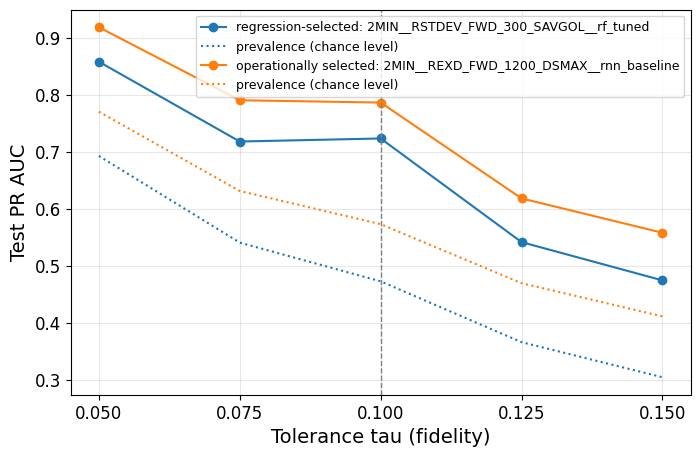

,role,config_id,tolerance,decision_threshold,prevalence,precision,recall,f1,false_positive_rate,roc_auc,pr_auc
2345,daylight baseline (reference),2MIN__REXD_FWD_1200_DSMAX__daylight_baseline,0.050,0.500000,0.770227,0.959184,0.592437,0.732468,0.084507,0.753965,0.932768
2346,daylight baseline (reference),2MIN__REXD_FWD_1200_DSMAX__daylight_baseline,0.075,0.500000,0.631068,0.857143,0.646154,0.736842,0.184211,0.730972,0.863299
2347,daylight baseline (reference),2MIN__REXD_FWD_1200_DSMAX__daylight_baseline,0.100,0.500000,0.572816,0.843537,0.700565,0.765432,0.174242,0.763161,0.857812
2348,daylight baseline (reference),2MIN__REXD_FWD_1200_DSMAX__daylight_baseline,0.125,0.500000,0.469256,0.721088,0.731034,0.726027,0.250000,0.740517,0.789168
2349,daylight baseline (reference),2MIN__REXD_FWD_1200_DSMAX__daylight_baseline,0.150,0.500000,0.411003,0.659864,0.763780,0.708029,0.274725,0.744527,0.760365
3875,daylight baseline (reference),2MIN__RSTDEV_FWD_300_SAVGOL__daylight_baseline,0.050,0.500000,0.692557,0.925170,0.635514,0.753463,0.115789,0.759862,0.906556
3876,daylight baseline (reference),2MIN__RSTDEV_FWD_300_SAVGOL__daylight_baseline,0.075,0.500000,0.540453,0.789116,0.694611,0.738854,0.218310,0.738150,0.824387
3877,daylight baseline (reference),2MIN__RSTDEV_FWD_300_SAVGOL__daylight_baseline,0.100,0.500000,0.472492,0.727891,0.732877,0.730375,0.245399,0.743739,0.793491
3878,daylight baseline (reference),2MIN__RSTDEV_FWD_300_SAVGOL__daylight_baseline,0.125,0.500000,0.365696,0.605442,0.787611,0.684615,0.295918,0.745846,0.735361
3879,daylight baseline (reference),2MIN__RSTDEV_FWD_300_SAVGOL__daylight_baseline,0.150,0.500000,0.304207,0.510204,0.797872,0.622407,0.334884,0.731494,0.684783


In [20]:
sens_ids = selected_ids + [daylight_id(cid) for cid in selected_ids]
sens = sim_test[sim_test["config_id"].isin(sens_ids)].copy()
sens["role"] = sens["config_id"].map({v: k for k, v in reversed(list(SELECTED.items()))}).fillna("daylight baseline (reference)")
sens = save_table(sens.sort_values(["role", "config_id", "tolerance"])[["role"] + SIM_COLS], "threshold_sensitivity_test")

fig, ax = plt.subplots(figsize=(8, 5))
for cid in selected_ids:
    s = sens[sens["config_id"] == cid]
    line, = ax.plot(s["tolerance"], s["pr_auc"], marker="o", label=f"{s['role'].iloc[0]}: {cid}")
    ax.plot(s["tolerance"], s["prevalence"], linestyle=":", color=line.get_color(), label="prevalence (chance level)")
ax.axvline(NOMINAL_TOLERANCE, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Tolerance tau (fidelity)")
ax.set_ylabel("Test PR AUC")
ax.set_xticks(TOLERANCES)
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
save_fig("threshold_sensitivity_pr_auc")
plt.show()
sens[["role", "config_id", "tolerance", "decision_threshold", "prevalence", "precision", "recall", "f1", "false_positive_rate", "roc_auc", "pr_auc"]]

## 8. Preprocessing factor tests on val metrics

Saved by NONLINEAR_MODELS (results/nonlinear/preprocessing_factor_tests.csv, nonlinear and NN models).

Printed and copied here where nothing is recomputed.

In [21]:
'''
def holm(p):
    p = np.asarray(p, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for k, i in enumerate(order):
        running = max(running, (len(p) - k) * p[i])
        adj[i] = min(1.0, running)
    return adj


def wilcoxon_row(a, b):
    d = (a - b).to_numpy()
    nz = d[d != 0]
    r = rankdata(np.abs(nz))
    rb = (r[nz > 0].sum() - r[nz < 0].sum()) / r.sum() if len(nz) else 0.0
    stat, p = wilcoxon(a, b) if len(nz) else (np.nan, 1.0)
    return {"statistic": stat, "p_value": p, "effect": rb, "effect_name": "rank-biserial r", "median_difference": np.median(d)}


def factor_test(df, value, factor, levels, block_cols, label):
    wide = df[df[factor].isin(levels)].pivot_table(index=block_cols, columns=factor, values=value, aggfunc="first")
    wide = wide[levels].dropna()
    base = {"factor": label, "metric": value, "n_blocks": len(wide), "matched_on": ", ".join(block_cols), **{f"median[{l}]": wide[l].median() for l in levels}}
    rows = []
    if len(levels) == 2:
        rows.append({**base, "test": "Wilcoxon", "comparison": f"{levels[0]} vs {levels[1]}", **wilcoxon_row(wide[levels[0]], wide[levels[1]])})
        rows[-1]["p_holm"] = rows[-1]["p_value"]
        return rows
    stat, p = friedmanchisquare(*[wide[l] for l in levels])
    rows.append({**base, "test": "Friedman", "comparison": " / ".join(map(str, levels)), "statistic": stat, "p_value": p, "effect": stat / (len(wide) * (len(levels) - 1)), "effect_name": "Kendall's W"})
    pairs = [(levels[i], levels[j]) for i in range(len(levels)) for j in range(i + 1, len(levels))]
    pair_rows = [{**base, "test": "Wilcoxon (pairwise)", "comparison": f"{a} vs {b}", **wilcoxon_row(wide[a], wide[b])} for a, b in pairs]
    for r, adj in zip(pair_rows, holm([r["p_value"] for r in pair_rows])):
        r["p_holm"] = adj
    return rows + pair_rows


FACTORS = [
    ("sampling frequency", "sampling", ["30SEC", "1MIN", "2MIN"], ["model", "target"]),
    ("target window", "window_samples", [300, 600, 1200], ["sampling", "model", "target_type", "variant"]),
    ("S-G filtering", "variant", ["SAVGOL", "DSMAX"], ["sampling", "model", "target_type", "window_samples"]),
    ("downsampling variant", "variant", ["DEC", "DSAVG", "DSMAX", "SAVGOL"], ["sampling", "model", "target_type", "window_samples"]),
    ("target type", "target_type", ["RSTDEV", "REXD"], ["sampling", "model", "window_samples", "variant"]),
]
sim_cand = candidates_sim.copy()
test_rows = []
for label, factor, levels, blocks in FACTORS:
    test_rows += factor_test(reg_val, "validation_r2", factor, levels, blocks, label)
    test_rows += factor_test(sim_cand, "pr_auc", factor, levels, blocks, label)
factor_tests = pd.DataFrame(test_rows)
factor_tests["metric"] = factor_tests["metric"].replace({"pr_auc": "validation PR AUC (tau = 0.10)", "validation_r2": "validation R^2"})
save_table(factor_tests, "preprocessing_factor_tests_validation")
factor_tests
'''
factor_tests = pd.read_csv(FACTOR_TESTS_PATH)
save_table(factor_tests, "preprocessing_factor_tests_validation")
factor_tests

,factor,metric,test,levels,n_blocks,statistic,p_value,significant
0,sampling frequency,validation_r2,Friedman,"['1MIN', '2MIN', '30SEC']",384,129.390625,8.001709e-29,True
1,sampling frequency,validation_rmse,Friedman,"['1MIN', '2MIN', '30SEC']",384,65.333333,6.501999e-15,True
2,window_samples,validation_r2,Friedman,"['300', '600', '1200']",384,120.161458,8.077386e-27,True
3,window_samples,validation_rmse,Friedman,"['300', '600', '1200']",384,688.380208,3.312356e-150,True
4,variant,validation_r2,Friedman,"['DEC', 'DSAVG', 'DSMAX', 'SAVGOL']",288,34.241667,1.761584e-07,True
5,variant,validation_rmse,Friedman,"['DEC', 'DSAVG', 'DSMAX', 'SAVGOL']",288,658.395833,2.202942e-142,True
6,metric,validation_r2,Wilcoxon,"['REXD', 'RSTDEV']",576,62678.000000,3.259123e-07,True
7,metric,validation_rmse,Wilcoxon,"['REXD', 'RSTDEV']",576,2292.000000,6.525061e-91,True


## 9. TSCV fold wise summary (robustness only)

Saved fold R^2/RMSE and train/val sizes per fold, with the saved mean/SD summary, for the two selected models and the TSCV top 5. NN baseline models have no TSCV runs.

In [22]:
'''
fold_summary = tscv_folds.groupby("config_id").agg(n_folds=("fold", "count"), mean_r2=("r2", "mean"), sd_r2=("r2", "std"), min_r2=("r2", "min"), max_r2=("r2", "max"), mean_rmse=("rmse", "mean"), sd_rmse=("rmse", "std"), n_train_min=("n_train", "min"), n_train_max=("n_train", "max"), n_val_min=("n_val", "min"), n_val_max=("n_val", "max")).reset_index()
save_table(fold_summary.sort_values("mean_r2", ascending=False), "tscv_fold_summary_all")
'''

report_ids = list(dict.fromkeys(selected_ids + top_tscv["config_id"].tolist()))
for role, cid in SELECTED.items():
    if cid not in set(tscv_folds["config_id"]):
        print(f"No TSCV for the {role} model ({cid}).")
fold_cols = ["config_id", "fold", "train_start", "train_end", "val_start", "val_end", "n_train", "n_val", "r2", "rmse"]
foldwise = tscv_folds[tscv_folds["config_id"].isin(report_ids)][fold_cols].sort_values(["config_id", "fold"])
save_table(foldwise, "tscv_foldwise_selected")
#save_table(fold_summary[fold_summary["config_id"].isin(report_ids)], "tscv_fold_summary_selected")
save_table(tscv_sum[tscv_sum["config_id"].isin(report_ids)][TSCV_COLS], "tscv_fold_summary_selected")

No TSCV for the operationally selected model (2MIN__REXD_FWD_1200_DSMAX__rnn_baseline).


,config_id,sampling,target,model,model_family,n_folds,mean_r2,std_r2,median_r2,r2_ci_low,r2_ci_high,pooled_r2,mean_rmse,std_rmse
126,1MIN__REXD_FWD_300_DSMAX__xgb_tuned,1MIN,REXD_FWD_300_DSMAX,xgb_tuned,nonlinear,3,0.441520,0.136694,0.447857,0.101953,0.781088,0.505970,0.055165,0.004246
187,2MIN__RSTDEV_FWD_300_SAVGOL__rf_tuned,2MIN,RSTDEV_FWD_300_SAVGOL,rf_tuned,nonlinear,3,0.035406,0.719519,0.170821,-1.751977,1.822790,0.127296,0.021392,0.007637
497,1MIN__RSTDEV_FWD_300_DSAVG__mlp_tuned,1MIN,RSTDEV_FWD_300_DSAVG,mlp_tuned,nn,3,0.422642,0.152042,0.447420,0.044949,0.800335,0.480089,0.009311,0.000593
569,2MIN__RSTDEV_FWD_300_DSAVG__gru_tuned,2MIN,RSTDEV_FWD_300_DSAVG,gru_tuned,nn,3,0.465491,0.132909,0.473473,0.135326,0.795656,0.526904,0.008662,0.000638
602,2MIN__REXD_FWD_1200_SAVGOL__mlp_tuned,2MIN,REXD_FWD_1200_SAVGOL,mlp_tuned,nn,3,0.415633,0.084957,0.368735,0.204588,0.626677,0.419308,0.128204,0.023915
616,2MIN__RSTDEV_FWD_300_DSAVG__mlp_tuned,2MIN,RSTDEV_FWD_300_DSAVG,mlp_tuned,nn,3,0.430021,0.106894,0.389252,0.164483,0.695559,0.484509,0.008985,0.000740


## 10. Test residual ACF and Ljung-Box for the selected models

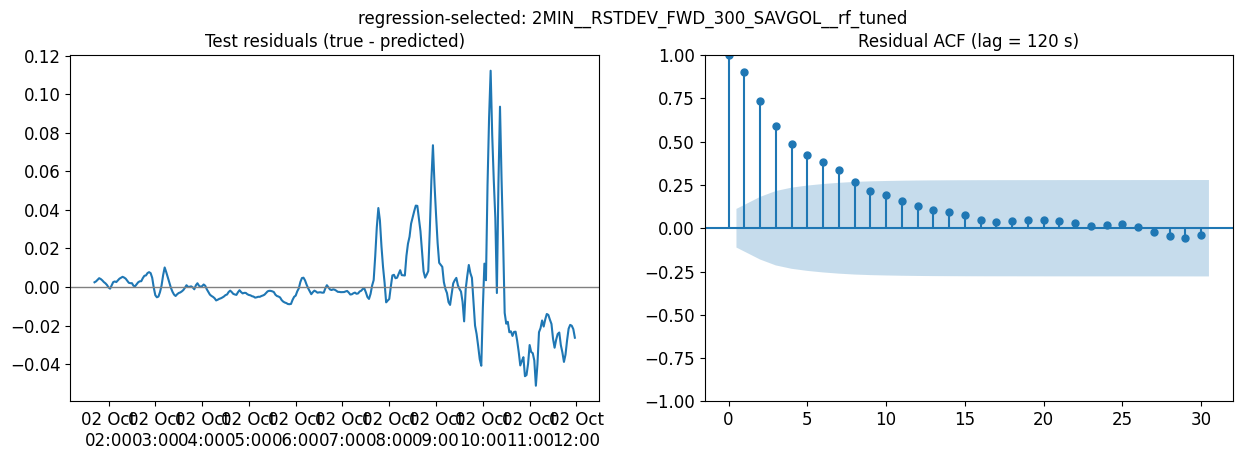

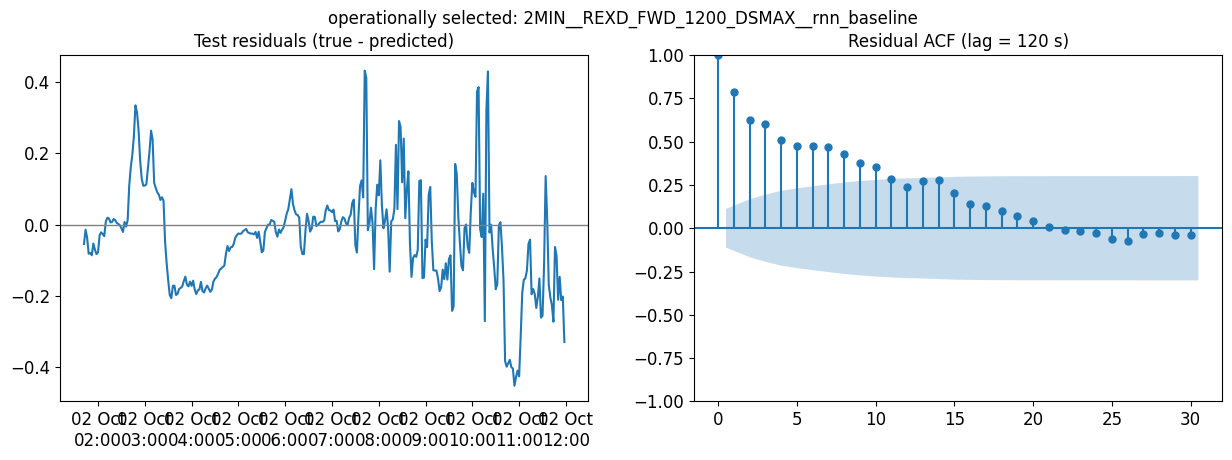

,role,config_id,requested_lag_min,actual_lag_min,lag,lb_stat,lb_pvalue
0,regression-selected,2MIN__RSTDEV_FWD_300_SAVGOL__rf_tuned,5,4.0,2,422.957782,1.431807e-92
1,regression-selected,2MIN__RSTDEV_FWD_300_SAVGOL__rf_tuned,10,10.0,5,664.076739,2.868633e-141
2,regression-selected,2MIN__RSTDEV_FWD_300_SAVGOL__rf_tuned,30,30.0,15,815.744457,3.686169e-164
3,regression-selected,2MIN__RSTDEV_FWD_300_SAVGOL__rf_tuned,60,60.0,30,823.202302,8.339611e-154
4,operationally selected,2MIN__REXD_FWD_1200_DSMAX__rnn_baseline,5,4.0,2,315.154887,3.672702e-69
5,operationally selected,2MIN__REXD_FWD_1200_DSMAX__rnn_baseline,10,10.0,5,581.591036,1.919088e-123
6,operationally selected,2MIN__REXD_FWD_1200_DSMAX__rnn_baseline,30,30.0,15,974.421399,4.082527e-198
7,operationally selected,2MIN__REXD_FWD_1200_DSMAX__rnn_baseline,60,60.0,30,997.133716,2.066465e-190


In [23]:
def local(ms):
    t = pd.to_datetime(ms, unit="ms", utc=True)
    return t.dt.tz_convert(TZ) if isinstance(t, pd.Series) else t.tz_convert(TZ)


def load_test(cid):
    df = pd.read_csv(PREDICTION_DIR / "test" / f"{cid}.csv")
    return df[df["split"] == "test"].sort_values("current_time")


lb_tables = []
for role, cid in SELECTED.items():
    pred = load_test(cid)
    step_s = SAMPLING_S[pred["sampling"].iloc[0]]
    resid = (pred["y_true"] - pred["y_pred"]).to_numpy()
    #lags = [l for l in sorted({max(1, round(m * 60 / step_s)) for m in LJUNG_BOX_LAGS_MIN}) if l < len(resid)]
    #lb = sms.acorr_ljungbox(resid, lags=lags, return_df=True).reset_index(names="lag")
    #lb.insert(0, "lag_min", lb["lag"] * step_s / 60)
    requested = {}
    for m in LJUNG_BOX_LAGS_MIN: # same lag rule as GENERAL_LINEAR_MODELS (round so 5 min at 2MIN is 2 lags = 4 min)
        requested.setdefault(max(1, round(m * 60 / step_s)), m)
    lags = [l for l in sorted(requested) if l < len(resid)]
    lb = sms.acorr_ljungbox(resid, lags=lags, return_df=True).reset_index(names="lag")
    lb.insert(0, "actual_lag_min", lb["lag"] * step_s / 60)
    lb.insert(0, "requested_lag_min", lb["lag"].map(requested))
    lb.insert(0, "config_id", cid)
    lb.insert(0, "role", role)
    lb_tables.append(lb)

    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(15, 4.5))
    ax0.plot(local(pred["current_time"]), resid)
    ax0.axhline(0, color="gray", linewidth=1)
    ax0.set_title("Test residuals (true - predicted)")
    ax0.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M", tz=TZ))
    plot_acf(resid, lags=max(1, int(RESIDUAL_ACF_MAX_LAG_MIN * 60 / step_s)), ax=ax1)
    ax1.set_title(f"Residual ACF (lag = {step_s} s)")
    fig.suptitle(f"{role}: {cid}")
    save_fig(f"test_residual_acf_{cid}")
    plt.show()

ljung_box = save_table(pd.concat(lb_tables, ignore_index=True), "test_residual_ljung_box")
ljung_box

NOTE: The actual 5-minute lag for 2-minute resolution data is rounded down to 4 in the code (since 5 obviously isnt evenly divisible by 2). I made a column to address this  that shows the requested versus the actual lag mins

## 11. Nominal static sim figs (test, tau = 0.10)

Same rules as STATIC_SIMULATION: anchored exceedance markers, labels from each predictions own window, and one horizontal line at the nominal decision threshold.

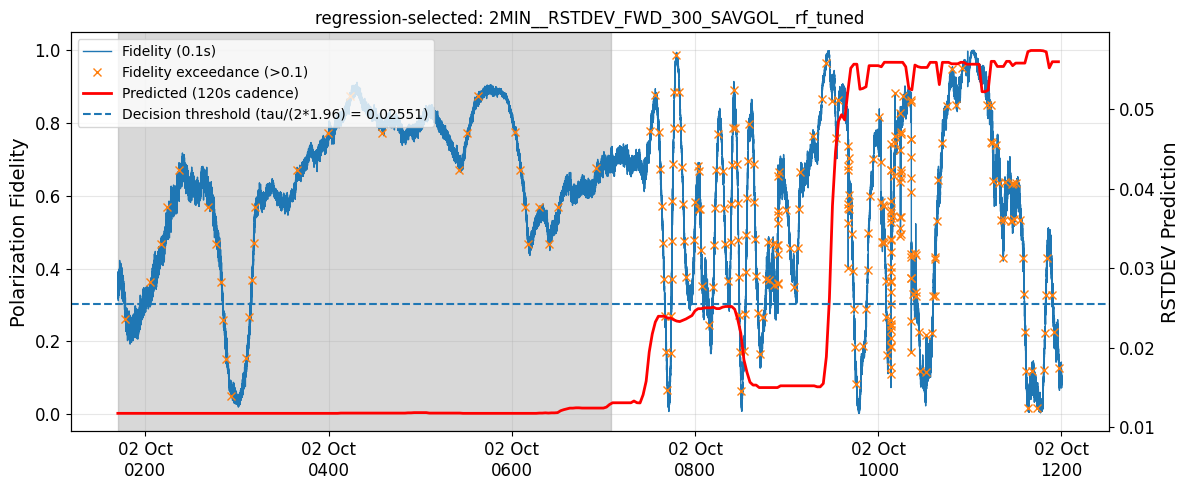

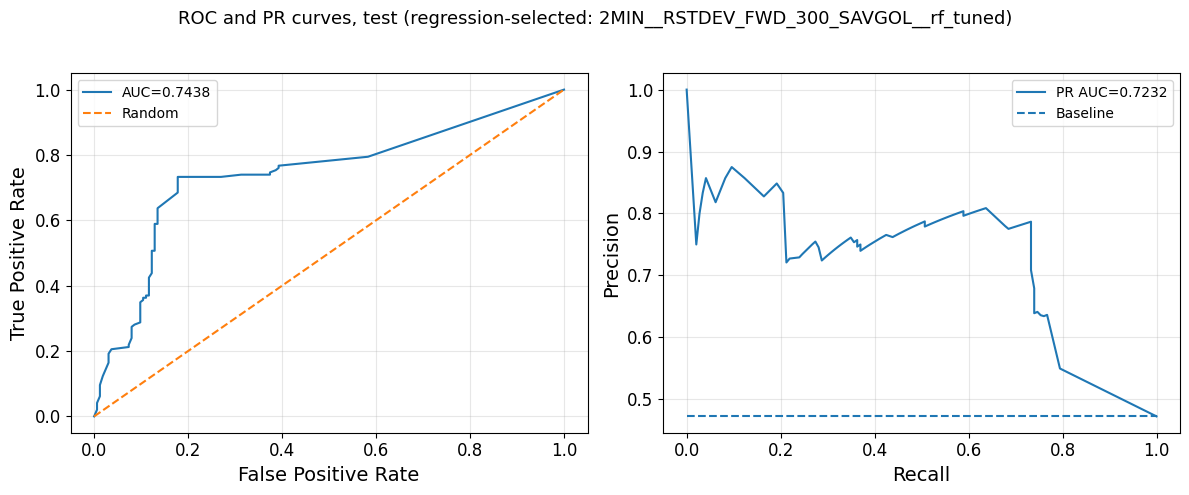

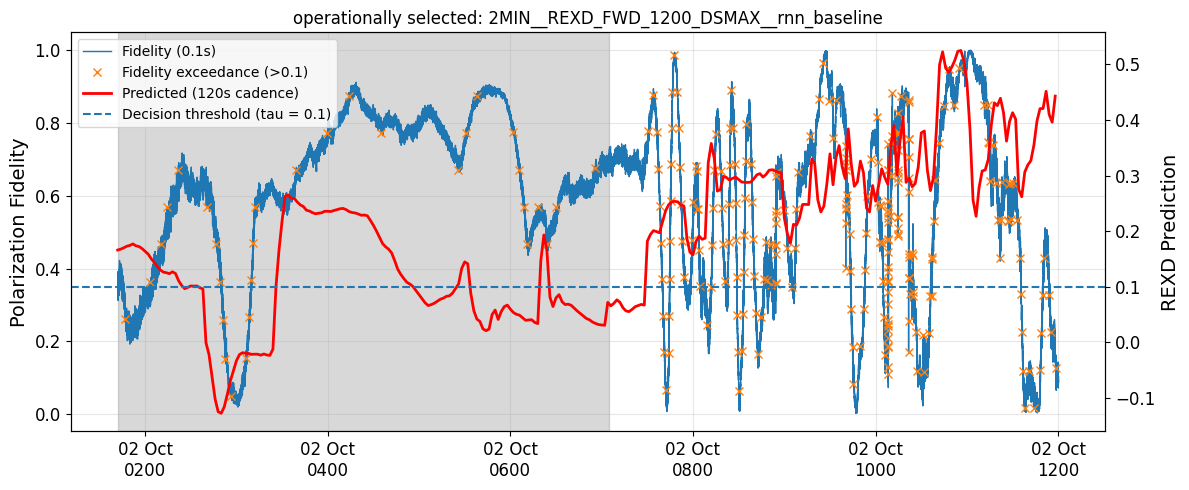

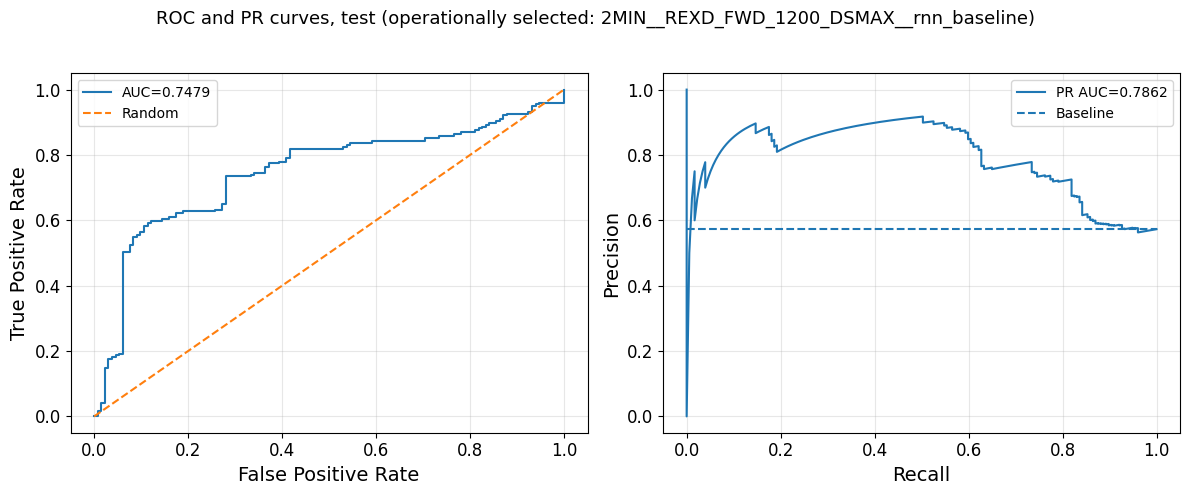

In [24]:
Z_975 = 1.959963985 # used excel's norm.s.inv for this calculation because that's how I learned to calculate the value from Mrs. S-K's class. There's probably a library for this


def target_decision_threshold(target_type, tolerance):
    if target_type == "REXD":
        return tolerance
    elif target_type == "RSTDEV":
        return tolerance / (2 * Z_975)


fid = pd.read_csv(manifest["files"]["fidelity_10hz"], usecols=["current_time", "Fidelity"]).dropna()
FID_T = fid["current_time"].to_numpy("int64")
FID_F = fid["Fidelity"].to_numpy(float)


def anchored_exceedance_markers(t0_ms, t1_ms, thresh):
    sel = (FID_T >= t0_ms) & (FID_T <= t1_ms)
    times, values = FID_T[sel], FID_F[sel]
    mark = np.zeros(len(values), dtype=bool)
    if len(values):
        anchor = values[0]
        for i in range(1, len(values)):
            if abs(values[i] - anchor) > thresh:
                mark[i] = True
                anchor = values[i]
    return times[mark]


def plot_selected(pred, role, tol):
    cid = f"{pred['sampling'].iloc[0]}__{pred['target'].iloc[0]}__{pred['model'].iloc[0]}"
    metric = pred["metric"].iloc[0]
    t = pred["current_time"].to_numpy("int64")
    start = t + pred["window_start_offset_s"].to_numpy() * 1000
    end = t + pred["window_end_offset_s"].to_numpy() * 1000
    markers = anchored_exceedance_markers(int(t.min()), int(end.max()), tol)
    labels = (np.searchsorted(markers, end, side="right") - np.searchsorted(markers, start, side="right")) > 0
    scores = pred["y_pred"].to_numpy(float)
    thr = target_decision_threshold(metric, tol)

    sel = (FID_T >= t.min()) & (FID_T <= end.max())
    fig, ax1 = plt.subplots(figsize=(12, 5))
    ax1.plot(local(FID_T[sel]), FID_F[sel], label="Fidelity (0.1s)", linewidth=1)
    ax1.plot(local(markers), np.interp(markers, FID_T, FID_F), linestyle="None", marker="x", label=f"Fidelity exceedance (>{tol})")
    ax1.set_ylabel("Polarization Fidelity")
    ax1.grid(alpha=0.3)
    
    for a, b in NIGHTS_MS:
        if a < end.max() and b > t.min():
            ax1.axvspan(local(max(a, t.min())), local(min(b, end.max())), alpha=0.3, color="gray", zorder=0)
            
    ax2 = ax1.twinx()
    ax2.plot(local(t), scores, color="red", linewidth=2, label=f"Predicted ({int(pred['sampling_s'].iloc[0])}s cadence)")
    ax2.axhline(thr, linestyle="--", linewidth=1.5, label=f"Decision threshold (tau/(2*1.96) = {thr:.4g})" if metric == "RSTDEV" else f"Decision threshold (tau = {thr:g})")
    ax2.set_ylabel(f"{metric} Prediction")
    ax1.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 2), tz=TZ))
    ax1.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H%M", tz=TZ))
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="upper left")
    ax1.set_title(f"{role}: {cid}")
    plt.tight_layout()
    save_fig(f"static_simulation_test_{cid}")
    plt.show()

    if labels.any() and (~labels).any():
        fpr, tpr, _ = roc_curve(labels, scores)
        precision, recall, _ = precision_recall_curve(labels, scores)
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
        fig.suptitle(f"ROC and PR curves, test ({role}: {cid})", fontsize=13)
        ax1.plot(fpr, tpr, label=f"AUC={roc_auc_score(labels, scores):.4f}")
        ax1.plot([0, 1], [0, 1], "--", label="Random")
        ax1.set_xlabel("False Positive Rate")
        ax1.set_ylabel("True Positive Rate")
        #ax2.plot(recall, precision, label=f"AP={average_precision_score(labels, scores):.4f}")
        ax2.plot(recall, precision, label=f"PR AUC={auc(recall, precision):.4f}")
        ax2.hlines(labels.mean(), 0, 1, linestyles="--", label="Baseline")
        ax2.set_xlabel("Recall")
        ax2.set_ylabel("Precision")
        
        for ax in (ax1, ax2):
            ax.legend()
            ax.grid(alpha=0.3)
            
        plt.tight_layout(rect=[0, 0, 1, 0.95])
        save_fig(f"roc_pr_test_{cid}")
        plt.show()


for role, cid in SELECTED.items():
    plot_selected(load_test(cid), role, NOMINAL_TOLERANCE)